# Hierarchical clustering

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://githubtocolab.com/EnriqueVilchezL/machine-learning/blob/main/book/04-unsupervised/hierarchical/hierarchical-notebook.ipynb)

Companion notebook for the *Hierarchical clustering* slides. Each idea is written first by hand
with NumPy and then with SciPy or scikit-learn doing the same job.

**Data:** 30 synthetic points in 2-D from `make_blobs`, generated around 3 centers. The labels are thrown away.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.cluster import hierarchy
from scipy.spatial.distance import pdist, squareform
from sklearn import cluster
from sklearn.datasets import make_blobs
from sklearn.metrics import adjusted_rand_score

RANDOM_STATE = 42
K = 3

X, _ = make_blobs(n_samples=30, centers=K, cluster_std=1.5, random_state=RANDOM_STATE)

## 1. Distance between examples

$d(\mathbf{a}, \mathbf{b}) = \sqrt{\sum_j (a_j - b_j)^2}$, for every pair of examples.

In [2]:
def distances(A: np.ndarray, B: np.ndarray) -> np.ndarray:
    """Euclidean distance from every row of A to every row of B."""
    return np.sqrt(((A[:, None, :] - B[None, :, :]) ** 2).sum(axis=2))


print("distance table:", distances(X, X).shape)
print("same result:", np.allclose(distances(X, X), squareform(pdist(X))))

distance table: (30, 30)
same result: True


## 2. Merging the closest pair

Start with every example alone and merge $(A^*, B^*) = \arg\min_{A \neq B} D(A, B)$, $n - 1$ times.
The linkage $D$ is the smallest (single), largest (complete) or mean (average) distance over all pairs $\mathbf{a} \in A$, $\mathbf{b} \in B$.
`fit` keeps the height of every merge in `distances_`, and the labels from the moment `n_clusters` clusters remain.

In [3]:
class AgglomerativeClustering:
    """Bottom-up clustering: merge the two closest clusters until only one is left."""

    LINKAGES = {"single": np.min, "complete": np.max, "average": np.mean}

    def __init__(self, n_clusters: int = 2, linkage: str = "average"):
        self.n_clusters, self.linkage = n_clusters, linkage

    def fit(self, X, y=None):
        d, rule = distances(X, X), self.LINKAGES[self.linkage]
        clusters, heights = [[i] for i in range(len(X))], []
        while True:
            if len(clusters) == self.n_clusters:
                self.labels_ = np.zeros(len(X), dtype=int)
                for k, members in enumerate(clusters):
                    self.labels_[members] = k
            if len(clusters) == 1:
                break
            height, a, b = min((rule(d[np.ix_(A, B)]), a, b)
                               for a, A in enumerate(clusters) for b, B in enumerate(clusters) if a < b)
            heights.append(height)
            clusters[a] += clusters.pop(b)
        self.distances_ = np.array(heights)
        return self

    def fit_predict(self, X, y=None):
        return self.fit(X).labels_

SciPy's `linkage` lists the same merge heights. scikit-learn gives the same grouping, up to the cluster numbers.

In [4]:
for method in AgglomerativeClustering.LINKAGES:
    by_hand = AgglomerativeClustering(n_clusters=K, linkage=method).fit(X)
    model = cluster.AgglomerativeClustering(n_clusters=K, linkage=method).fit(X)
    same_heights = np.allclose(np.sort(by_hand.distances_), hierarchy.linkage(X, method)[:, 2])
    same_grouping = adjusted_rand_score(by_hand.labels_, model.labels_) == 1.0
    print(f"{method:8} {len(by_hand.distances_)} merges | same heights: {same_heights} | same grouping: {same_grouping}")

single   29 merges | same heights: True | same grouping: True
complete 29 merges | same heights: True | same grouping: True
average  29 merges | same heights: True | same grouping: True


## 3. Ward's linkage

Ward merges the pair whose within-cluster sum of squares $W(A) = \sum_{\mathbf{a} \in A} \lVert \mathbf{a} - \boldsymbol{\mu}_A \rVert^2$ grows the least:
$\Delta(A, B) = \frac{|A|\,|B|}{|A| + |B|} \lVert \boldsymbol{\mu}_A - \boldsymbol{\mu}_B \rVert^2$.
We check it on the last merge, which joins the two clusters of the cut into $K = 2$.
SciPy reports the height $\sqrt{2\Delta}$.

In [5]:
ward_tree = hierarchy.linkage(X, "ward")
two = hierarchy.fcluster(ward_tree, t=2, criterion="maxclust")
A, B = X[two == 1], X[two == 2]


def within(C: np.ndarray) -> float:
    """Sum of squared distances from each example to the mean of its cluster."""
    return ((C - C.mean(axis=0)) ** 2).sum()


delta = len(A) * len(B) / (len(A) + len(B)) * ((A.mean(axis=0) - B.mean(axis=0)) ** 2).sum()
print("formula matches W growth:", np.isclose(delta, within(np.vstack([A, B])) - within(A) - within(B)))
print("same height:", np.isclose(np.sqrt(2 * delta), ward_tree[-1, 2]))

formula matches W growth: True
same height: True


## 4. Reading and cutting the dendrogram

Each join sits at the height of its merge. A cut across the tree gives one cluster per branch it crosses;
a good cut sits in a long gap between joins.

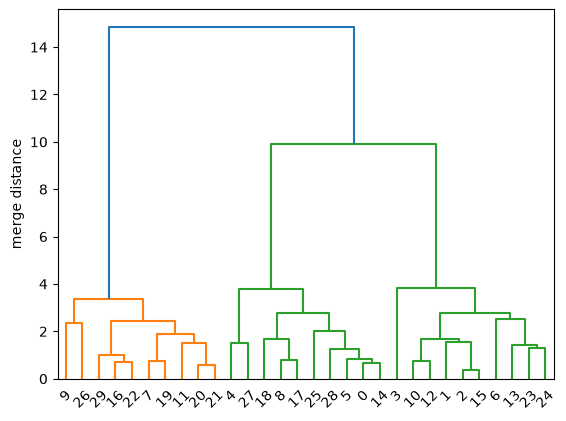

In [6]:
average_tree = hierarchy.linkage(X, "average")
hierarchy.dendrogram(average_tree)
plt.ylabel("merge distance")
plt.show()

Cutting SciPy's tree into $K$ branches gives the clusters our class kept when $K$ were left.

In [7]:
cut_labels = hierarchy.fcluster(average_tree, t=K, criterion="maxclust")
by_hand = AgglomerativeClustering(n_clusters=K, linkage="average")
print("same grouping:", adjusted_rand_score(cut_labels, by_hand.fit_predict(X)) == 1.0)

same grouping: True


## Exercises

1. Add the point `(30, 30)` to `X` and draw the dendrogram again. Where does it join?
2. Cut the average-linkage tree at the height `t=5` with `criterion="distance"`. How many clusters do you get?
3. Multiply the second feature by 100 and compare the single-linkage clusters before and after, with `adjusted_rand_score`.